# Video Game Sales: Data Space and Projection Space
**Project – data exploration and interaction • ITCS 4123/5123 • November 19, 2026**  
**Team:** Anderson Zhu, Krish Thakre, and Vasista Vegesana

This extension of the Video Game Sales Explorer asks whether releases that appear similar in a 2D map also have similar regional sales and release years. It pairs **PCA (linear)** with **t-SNE (nonlinear)** and links both to original feature views. The prior project used the same `vgsales.csv` and aggregate genre, region, platform, and era views; this extension changes the unit of exploration to individual game-platform releases.

**Reading guide:** Start with the data audit, compare PCA and t-SNE, then inspect the LAMP bonus and its before/after example. Each section explains its purpose before showing code and results. The offline `Interactive_Explorer.html` provides the linked interactions. Sales are in millions of units; a point represents one game-platform release.

| Canvas requirement | Evidence |
|---|---|
| Two DR methods (2 points) | Standardized five-feature PCA and t-SNE, same records and inputs |
| Original vs. projected spaces (2 points) | Distribution plots, correlation/loadings, distance/neighborhood metrics, and linked raw-feature scatter |
| Joint exploration (4 points) | Box/lasso or click in either map or raw scatter; shared highlights, profiles, distributions, records, genre and feature filters |
| Documentation (2 points) | Executed code, outputs, methodology, analysis, prompt disclosure, references |
| Peer evaluation | Separate form with user-provided 100% ratings for all three members |
| Approved bonus (10 possible points) | Featured-paper LAMP solver, movable controls, linked selection, reset, distortion evaluation |

**Bonus: LAMP feature-paper implementation.** The user confirmed instructor approval before implementation on November 19, 2026. The extension below implements the paper's local orthogonal affine mapping, interactive control-point steering, linked inspection, and quantitative before/after evaluation. Approval is recorded from the user's confirmation; no instructor email is reproduced here.

In [1]:
from pathlib import Path
import json, base64, hashlib, platform, warnings
import numpy as np
if np.lib.NumpyVersion(np.__version__) < '2.3.5':
    raise RuntimeError('Select the project Python environment with NumPy 2.3.5 or newer, then restart the kernel and Run All. See README.md for setup. Older NumPy on this Mac produces misleading matrix-multiplication warnings.')
# Unexpected numerical warnings are errors: invalid computations cannot be hidden in the report.
warnings.filterwarnings('error', category=RuntimeWarning)
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import NearestNeighbors
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
from IPython.display import display, HTML, Markdown, IFrame
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from plotly.offline import get_plotlyjs

ROOT = Path.cwd()
DATA = ROOT / 'vgsales.csv'
SEED = 42
print('Environment: Python', platform.python_version(), '| NumPy', np.__version__, '| scikit-learn', sklearn.__version__)
print('Dataset SHA256:', hashlib.sha256(DATA.read_bytes()).hexdigest())
raw = pd.read_csv(DATA)
regions = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']
features = regions + ['Year']
clean = raw.copy()
for c in features + ['Global_Sales']:
    clean[c] = pd.to_numeric(clean[c], errors='coerce')
valid = (clean.Year.between(1980, 2016) & clean[features + ['Global_Sales']].notna().all(axis=1)
         & clean[['Name','Genre','Platform']].notna().all(axis=1)
         & clean[regions + ['Global_Sales']].ge(0).all(axis=1))
clean = clean.loc[valid].copy()
clean['Source_Row'] = clean.index
# A simple random sample preserves approximate frequency, without selecting visually attractive examples.
df = clean.sample(n=min(2000, len(clean)), random_state=SEED).sort_index().reset_index(drop=True)
df['Year'] = df.Year.astype(int)
transformed = df[features].copy()
transformed[regions] = np.log1p(transformed[regions])
scaler = StandardScaler()
X = scaler.fit_transform(transformed)
assert np.isfinite(X).all(), 'Preprocessing must produce finite values.'
assert np.all(X.std(axis=0)>0), 'All embedding dimensions must vary.'
display(pd.DataFrame({'Stage':['Raw','Clean','Embedded sample'], 'Rows':[len(raw),len(clean),len(df)]}))
display(df[features].describe().round(3))
print('Sample genre counts:'); display(df.Genre.value_counts().to_frame('Releases'))

Environment: Python 3.13.9 | NumPy 2.3.5 | scikit-learn 1.7.2
Dataset SHA256: 938ae2e906305d57245405a27e2da49c05aaa96c007d33a9656e8f1bac40eb75


,Stage,Rows
0,Raw,16539
1,Clean,16287
2,Embedded sample,2000


,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Year
count,2000.000,2000.000,2000.000,2000.000,2000.000
mean,0.247,0.138,0.073,0.045,2006.398
std,0.634,0.472,0.270,0.162,5.842
min,0.000,0.000,0.000,0.000,1980.000
25%,0.000,0.000,0.000,0.000,2003.000
50%,0.080,0.020,0.000,0.010,2007.000
75%,0.230,0.100,0.030,0.030,2010.000
max,15.850,12.880,3.810,4.140,2016.000


Sample genre counts:


,Releases
Genre,
Action,400
Sports,278
Misc,204
Role-Playing,171
Adventure,163
Shooter,159
Racing,156
Platform,116
Simulation,107


## Representation and method choices
Each row is a **game-platform release**, not a unique franchise or player. Five original numeric dimensions enter the embedding: four regional sales values (millions of units) and release year. Regional sales receive `log1p` to reduce blockbuster skew, followed by z-score scaling of all five dimensions so year and a large region do not dominate merely through their units. Thus distance means similarity in transformed regional sales and release timing. This choice gives each region and year equal variance, not equal commercial importance.

`Global_Sales` is excluded because it approximately sums the regions; rank is also excluded because it derives from sales. Genre/platform/publisher are metadata for interpretation, not numeric codes injected into Euclidean distance. The five-dimensional representation is modest, but two dimensions still discard structure. A seeded uniform sample of 2,000 clean records keeps linked interaction responsive; all conclusions and metrics below refer to that sample. Missing years are removed, rather than imputed with unsupported chronology. Sampling can miss rare releases.

PCA maximizes retained variance using an orthogonal linear subspace, with interpretable loadings and reconstruction. t-SNE optimizes neighborhood probability agreement using a nonlinear layout. It is suitable for checking local similarities, but inter-island distances, island areas, and apparent gaps do not establish real categories. Both methods receive identical `X`; neither sees genre labels. PCA uses full SVD; t-SNE uses Euclidean distance, PCA initialization, automatic learning rate, 1,000 iterations, seed 42 and perplexity 30. Additional perplexity/seed settings below test sensitivity rather than choosing the prettiest map.

In [2]:
pca = PCA(n_components=2, svd_solver='full')
P = pca.fit_transform(X)
settings = [(30,42), (10,42), (50,42), (30,7)]
embeddings = {}
for perplexity, seed in settings:
    model = TSNE(n_components=2, perplexity=perplexity, random_state=seed,
                 init='pca', learning_rate='auto', max_iter=1000)
    embeddings[(perplexity, seed)] = model.fit_transform(X)
T = embeddings[(30,42)]
assert np.isfinite(P).all() and all(np.isfinite(Z).all() for Z in embeddings.values())
loadings = pd.DataFrame(pca.components_.T, index=features, columns=['PC1','PC2'])
display(loadings.round(3))
print('Variance explained per PC:', pca.explained_variance_ratio_.round(4))
print('Total retained variance:', pca.explained_variance_ratio_.sum().round(4))
print('Reconstruction MSE in standardized input space:', np.mean((X-pca.inverse_transform(P))**2).round(4))

,PC1,PC2
NA_Sales,0.548,-0.029
EU_Sales,0.570,0.144
JP_Sales,0.268,-0.533
Other_Sales,0.549,0.203
Year,-0.043,0.808


Variance explained per PC: [0.526  0.2321]
Total retained variance: 0.7581
Reconstruction MSE in standardized input space: 0.2419


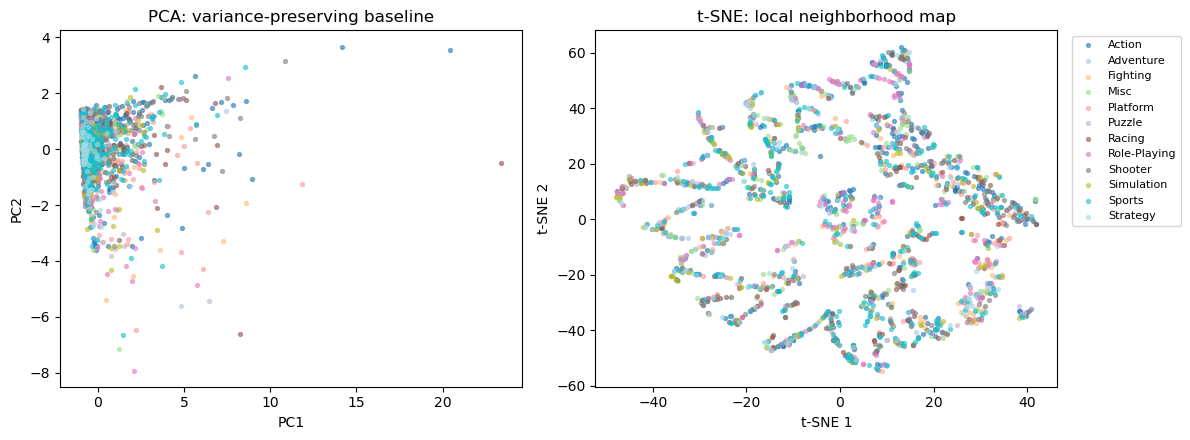

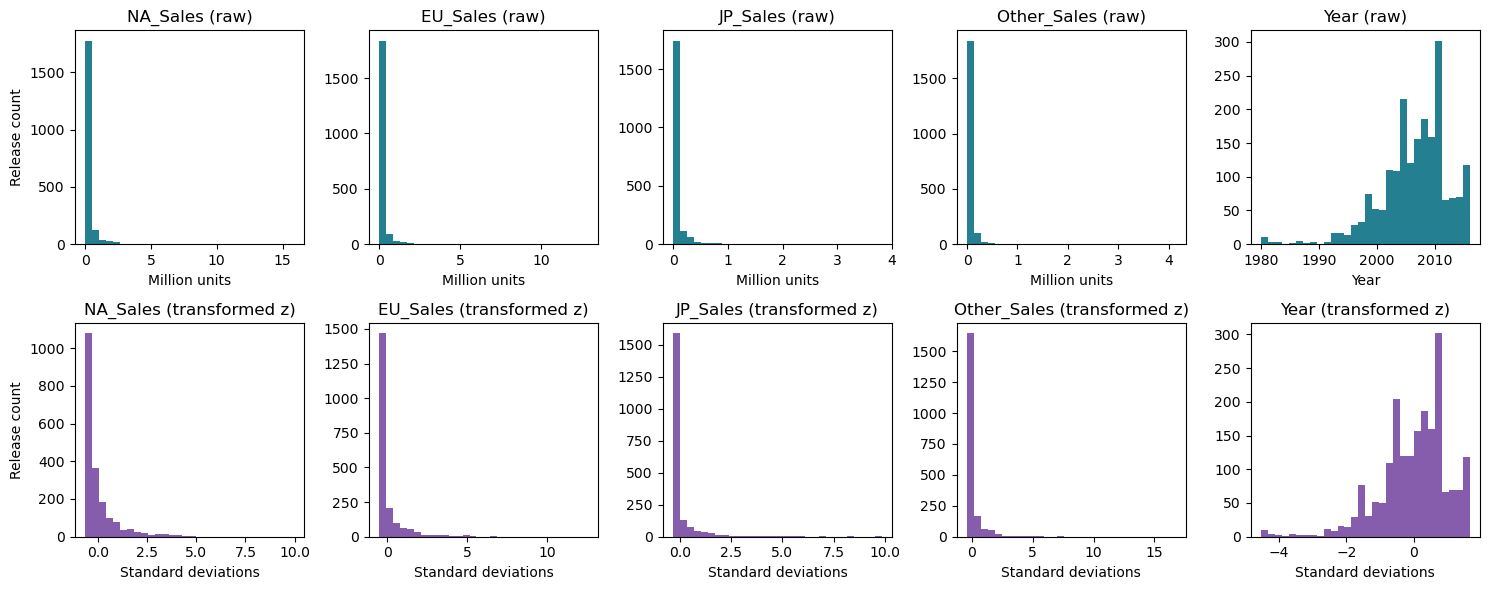

,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Year
NA_Sales,1.000,0.766,0.280,0.685,-0.129
EU_Sales,0.766,1.000,0.250,0.806,0.018
JP_Sales,0.280,0.250,1.000,0.241,-0.201
Other_Sales,0.685,0.806,0.241,1.000,0.081
Year,-0.129,0.018,-0.201,0.081,1.000


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
genres = sorted(df.Genre.unique())
colors = plt.get_cmap('tab20')(np.linspace(0,1,len(genres)))
genre_color = dict(zip(genres, colors))
for ax, Z, title in zip(axes, [P,T], ['PCA: variance-preserving baseline','t-SNE: local neighborhood map']):
    for genre in genres:
        mask = df.Genre.eq(genre)
        ax.scatter(Z[mask,0], Z[mask,1], s=8, alpha=.55, color=genre_color[genre], label=genre)
    ax.set_title(title); ax.set_xlabel('PC1' if Z is P else 't-SNE 1'); ax.set_ylabel('PC2' if Z is P else 't-SNE 2')
axes[1].legend(bbox_to_anchor=(1.02,1), fontsize=8)
fig.tight_layout(); fig.savefig('projection_comparison.png', dpi=160, bbox_inches='tight'); plt.show()

fig, axes = plt.subplots(2,5,figsize=(15,6))
for j,c in enumerate(features):
    axes[0,j].hist(df[c],bins=30,color='#247f91'); axes[0,j].set_title(c+' (raw)')
    axes[1,j].hist(X[:,j],bins=30,color='#865cad'); axes[1,j].set_title(c+' (transformed z)')
    axes[0,j].set_xlabel('Year' if c=='Year' else 'Million units')
    axes[1,j].set_xlabel('Standard deviations')
axes[0,0].set_ylabel('Release count'); axes[1,0].set_ylabel('Release count')
fig.tight_layout(); fig.savefig('feature_distributions.png',dpi=160); plt.show()
display(pd.DataFrame(X,columns=features).corr().round(3))

## Comparing what each map preserves
We evaluate trustworthiness (penalty for false neighbors; 1 is best), exact 10-neighbor overlap (higher is better), and Spearman correlation between original and embedded pairwise distances (a global ordering diagnostic). These capture different properties and are not interchangeable. Tied observations can make exact neighbor overlap sensitive to tie breaking. Metrics use the same complete 2,000-record sample, with deterministic 600-record subsampling only for pairwise-distance correlation. They are descriptive in-sample checks, not predictive accuracy or evidence that clusters are ground truth.

In [4]:
def neighbors(Z):
    return NearestNeighbors(n_neighbors=11).fit(Z).kneighbors(Z, return_distance=False)
def neighbor_sets(Z):
    # Remove self explicitly: identical inputs may reorder tied neighbors.
    return [set(row[row != i][:10]) for i,row in enumerate(neighbors(Z))]
original_n = neighbor_sets(X)
idx = np.random.default_rng(SEED).choice(len(X),min(600,len(X)),replace=False)
original_dist = pdist(X[idx])
def evaluate(name,Z):
    sets = neighbor_sets(Z)
    return {'Method':name, 'Trustworthiness k=10':trustworthiness(X,Z,n_neighbors=10),
            '10-neighbor overlap':np.mean([len(a&b)/10 for a,b in zip(original_n,sets)]),
            'Distance rank correlation':spearmanr(original_dist,pdist(Z[idx])).statistic}
metrics = pd.DataFrame([evaluate('PCA',P)] + [evaluate(f't-SNE p={p}, seed={s}',Z) for (p,s),Z in embeddings.items()])
display(metrics.round(4))
metrics.to_csv('metrics.csv',index=False)
assert np.isfinite(metrics.select_dtypes('number').to_numpy()).all()
df.assign(PC1=P[:,0],PC2=P[:,1],TSNE1=T[:,0],TSNE2=T[:,1]).to_csv('sample_projections.csv',index=False)

pc1 = loadings.PC1.abs().idxmax(); pc2 = loadings.PC2.abs().idxmax()
base = metrics.iloc[1]; baseline = metrics.iloc[0]
display(Markdown(f"""### Results grounded in the computed sample
PCA retains **{pca.explained_variance_ratio_.sum():.1%}** of standardized variance in two axes.
The largest absolute loading is **{pc1}** on PC1 and **{pc2}** on PC2 (signs can flip without changing the solution).
PCA trustworthiness is **{baseline['Trustworthiness k=10']:.3f}** versus **{base['Trustworthiness k=10']:.3f}** for the primary t-SNE run;
10-neighbor overlap is **{baseline['10-neighbor overlap']:.3f}** versus **{base['10-neighbor overlap']:.3f}**.
The distance-rank diagnostic is **{baseline['Distance rank correlation']:.3f}** for PCA and **{base['Distance rank correlation']:.3f}** for t-SNE.
Across the three tested perplexities, t-SNE retains higher neighborhood scores but lower distance-rank correlation than PCA. PC1 is dominated by NA/EU/Other sales (loadings about 0.55–0.57); PC2 contrasts later years (0.81) with Japanese sales (-0.53). Thus the broad PCA direction largely expresses sales magnitude, while its vertical direction mixes timing and regional preference. The two seed runs coincide here because PCA initialization is deterministic for this small dense input; this is limited seed evidence, not proof of stability under arbitrary initializations. Coordinates themselves are not directly comparable across different perplexities.
"""))

,Method,Trustworthiness k=10,10-neighbor overlap,Distance rank correlation
0,PCA,0.9165,0.4280,0.9420
1,"t-SNE p=30, seed=42",0.9957,0.7457,0.3483
2,"t-SNE p=10, seed=42",0.9937,0.7240,0.3141
3,"t-SNE p=50, seed=42",0.9948,0.7371,0.4600
4,"t-SNE p=30, seed=7",0.9957,0.7457,0.3483


### Results grounded in the computed sample
PCA retains **75.8%** of standardized variance in two axes.
The largest absolute loading is **EU_Sales** on PC1 and **Year** on PC2 (signs can flip without changing the solution).
PCA trustworthiness is **0.916** versus **0.996** for the primary t-SNE run;
10-neighbor overlap is **0.428** versus **0.746**.
The distance-rank diagnostic is **0.942** for PCA and **0.348** for t-SNE.
Across the three tested perplexities, t-SNE retains higher neighborhood scores but lower distance-rank correlation than PCA. PC1 is dominated by NA/EU/Other sales (loadings about 0.55–0.57); PC2 contrasts later years (0.81) with Japanese sales (-0.53). Thus the broad PCA direction largely expresses sales magnitude, while its vertical direction mixes timing and regional preference. The two seed runs coincide here because PCA initialization is deterministic for this small dense input; this is limited seed evidence, not proof of stability under arbitrary initializations. Coordinates themselves are not directly comparable across different perplexities.


## Bonus — Local Affine Multidimensional Projection (LAMP)
**Featured paper P1:** Joia et al. (2011), *Local Affine Multidimensional Projection*, IEEE TVCG 17(12), 2563–2571. https://doi.org/10.1109/TVCG.2011.220

The course's HW4 already proposed applying this paper to the Video Game Sales Explorer. This implementation retains its core mechanism: choose representative control records, position them in 2D, then fit a separate weighted orthogonal affine map for every remaining record. Moving a control changes those local maps rather than merely translating a plotted marker. The original features remain fixed.

For an input x and controls C with target coordinates Y, we use inverse-Euclidean weights w_i = 1 / ||x-C_i||, normalize them, and compute weighted centers xbar and ybar. The d-by-2 cross-covariance is H = sum_i w_i (C_i-xbar)(Y_i-ybar)^T. If H = U S V^T, the least-squares orthogonal solution is M = U V^T; the output is (x-xbar)M + ybar. Exact matches map directly to control targets. This is the LAMP local orthogonal-fitting approach. Positive inverse-distance weights follow the authors' Python reference configuration, rather than claiming a verbatim reproduction of every paper setting.

**Adaptation scope:** use the same 2,000 records and five standardized numeric inputs as PCA/t-SNE so comparison is fair; choose 24 controls with deterministic farthest-point coverage, starting near the centroid; initialize their target positions with classical metric MDS of their original distances. Keep target coordinates in that MDS scale, without optional automatic control rescaling. This is a smaller scope than HW4's proposed categorical feature blocks, full-data rendering and Bokeh architecture: it implements the core paper method and linked steering in an offline browser instead. We make no claim of reproducing the full research system, its performance results, or a human-subject evaluation.

The NumPy reference below uses SVD. The browser independently solves the equivalent d-by-2 orthogonal factor from the 2-by-2 Gram matrix, including rank-deficient completion, and is checked numerically against NumPy. This avoids a remote computation service. The authors' implementation was consulted as a reference, not copied: https://github.com/lgnonato/LAMP

In [5]:
"""Local orthogonal affine fitting, following Joia et al. (TVCG 2011).

Independent NumPy implementation; inverse-Euclidean weighting follows the
authors' reference implementation at https://github.com/lgnonato/LAMP.
No optional automatic rescaling: controls stay in the initial metric-MDS units.
"""
import numpy as np
from scipy.spatial.distance import cdist


def choose_controls(X, count=24):
    """Deterministic farthest-point coverage, starting near the data centroid."""
    X = np.asarray(X, dtype=float)
    chosen = [int(np.argmin(np.sum((X-X.mean(axis=0))**2, axis=1)))]
    nearest = np.full(len(X), np.inf)
    while len(chosen) < min(count, len(X)):
        nearest = np.minimum(nearest, np.sum((X-X[chosen[-1]])**2, axis=1))
        nearest[chosen] = -1
        nxt = int(np.argmax(nearest))
        if nearest[nxt] <= 1e-16:
            break
        chosen.append(nxt)
    return np.array(chosen)


def classical_mds(X):
    """Classical metric MDS of Euclidean control distances into two dimensions."""
    squared = cdist(X, X, 'sqeuclidean')
    centered = -.5*(squared-squared.mean(axis=0)-squared.mean(axis=1)[:,None]+squared.mean())
    vals, vecs = np.linalg.eigh(centered)
    order = np.argsort(vals)[::-1][:2]
    return vecs[:,order]*np.sqrt(np.maximum(vals[order],0))


def project(X, control_ids, targets):
    """Fit M per input record with M.T @ M = I and map about weighted centers.

    Given C= X[control_ids], each local cross covariance is
    H = (C-xbar).T @ diag(w) @ (targets-ybar). For H=U S V.T,
    the orthogonal least-squares solution is M=U @ V.T.
    Exact control matches interpolate the supplied target without division by 0.
    """
    X = np.asarray(X, dtype=float)
    control_ids = np.asarray(control_ids, dtype=int)
    targets = np.asarray(targets, dtype=float)
    if X.ndim != 2 or X.shape[1] < 2 or targets.shape != (len(control_ids),2):
        raise ValueError('Expected N x d input (d>=2) and m x 2 control targets')
    if len(control_ids) < 3 or len(set(control_ids)) != len(control_ids):
        raise ValueError('Use at least three distinct control IDs')
    if not np.isfinite(X).all() or not np.isfinite(targets).all():
        raise ValueError('Inputs and controls must be finite')
    C = X[control_ids]
    distances = cdist(X,C)
    result = np.empty((len(X),2))
    for i,x in enumerate(X):
        close = np.flatnonzero(distances[i] <= 1e-10)
        if len(close):
            result[i] = targets[close[0]]
            continue
        weights = 1 / distances[i]
        weights /= weights.sum()
        xbar = weights @ C
        ybar = weights @ targets
        H = (C-xbar).T @ (weights[:,None]*(targets-ybar))
        U, _, Vt = np.linalg.svd(H, full_matrices=False)
        result[i] = (x-xbar) @ (U@Vt)+ybar
    return result

,Method,Trustworthiness k=10,10-neighbor overlap,Distance rank correlation
0,LAMP: MDS controls,0.8737,0.2881,0.8393
1,"LAMP: crafted control +2,-2",0.8711,0.2881,0.8401


Live metric reference: mean exact 10-neighbor overlap on 200 fixed probes: 0.3085
Control interpolation max error: 0.0
Non-control mean movement: 0.06626059783078353
Crafted control: {'Name': 'Super Mario Kart', 'Platform': 'SNES', 'Source_Row': 284}


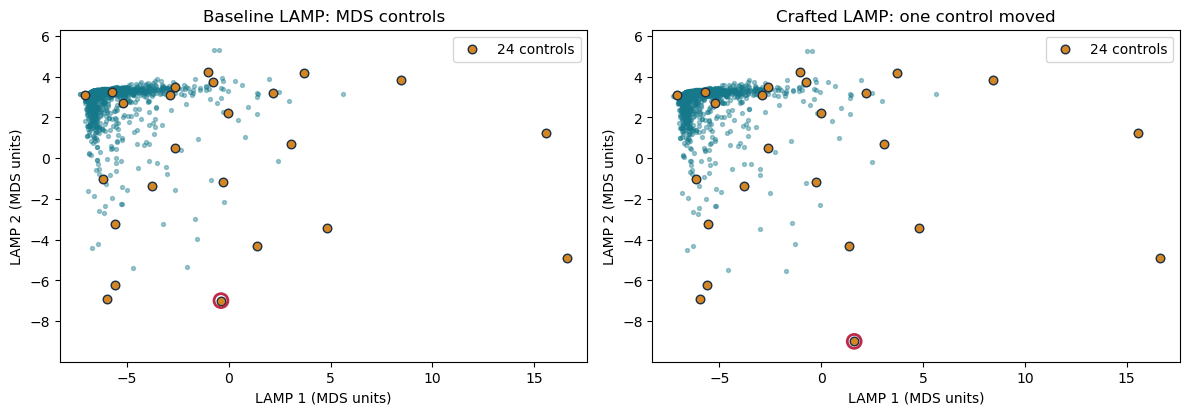

The crafted control move changes full-sample trustworthiness from **0.8737** to **0.8711**, and neighbor overlap from **0.2881** to **0.2881**. Steering is not automatically an improvement: the crafted map expresses an analyst decision and must be checked against the unchanged feature views. Reset restores the exact baseline coordinates.

For this control configuration, baseline LAMP trustworthiness (**0.874**) is below PCA (**0.916**), and its distance-rank correlation is also lower. The benefit demonstrated here is user-directed local steering with linked verification, not a numerical improvement over PCA or t-SNE. Farthest-point controls deliberately cover extremes, so their MDS layout need not optimize preservation for the dense bulk of releases.

In [6]:
control_ids = choose_controls(X,24)
control_targets = classical_mds(X[control_ids])
L = project(X,control_ids,control_targets)
# A deliberately crafted state: move the control with highest Japanese sales.
control_slot = int(np.argmax(df.iloc[control_ids].JP_Sales.to_numpy()))
steered_targets = control_targets.copy()
steered_targets[control_slot] += np.array([2.0,-2.0])
LS = project(X,control_ids,steered_targets)
lamp_metrics = pd.DataFrame([evaluate('LAMP: MDS controls',L), evaluate('LAMP: crafted control +2,-2',LS)])
display(lamp_metrics.round(4)); lamp_metrics.to_csv('lamp_metrics.csv',index=False)
assert np.allclose(L[control_ids],control_targets,atol=1e-10)
assert np.allclose(LS[control_ids],steered_targets,atol=1e-10)
assert np.isfinite(LS).all() and np.max(np.linalg.norm(LS-L,axis=1))>0.1
restored = project(X,control_ids,control_targets)
assert np.allclose(restored,L,atol=1e-12)
probe_ids = np.random.default_rng(42).choice(len(X),200,replace=False)
def stable_knn(Z, i):
    dist = np.sum((Z-Z[i])**2,axis=1)
    return sorted((j for j in range(len(Z)) if j!=i),key=lambda j:(dist[j],j))[:10]
probe_neighbors = [stable_knn(X,int(i)) for i in probe_ids]
def probe_overlap(Z):
    return np.mean([len(set(stable_knn(Z,int(i))) & set(near))/10 for i,near in zip(probe_ids,probe_neighbors)])
probe_baseline = float(probe_overlap(L))
print('Live metric reference: mean exact 10-neighbor overlap on 200 fixed probes:',round(probe_baseline,4))
print('Control interpolation max error:',np.max(np.abs(L[control_ids]-control_targets)))
print('Non-control mean movement:',np.mean(np.linalg.norm(LS-L,axis=1)[~np.isin(np.arange(len(X)),control_ids)]))
print('Crafted control:',df.iloc[control_ids[control_slot]][['Name','Platform','Source_Row']].to_dict())
fig,axes=plt.subplots(1,2,figsize=(12,5))
limits=np.vstack([L,LS]); xlim=(limits[:,0].min()-1,limits[:,0].max()+1); ylim=(limits[:,1].min()-1,limits[:,1].max()+1)
for ax,Z,title,targets in zip(axes,[L,LS],['Baseline LAMP: MDS controls','Crafted LAMP: one control moved'],[control_targets,steered_targets]):
    ax.scatter(Z[:,0],Z[:,1],s=8,c='#16798b',alpha=.4)
    ax.scatter(targets[:,0],targets[:,1],s=38,c='#d58623',edgecolor='#183047',label='24 controls')
    ax.scatter(*targets[control_slot],s=100,facecolor='none',edgecolor='#bd2948',linewidth=2)
    ax.set(xlabel='LAMP 1 (MDS units)',ylabel='LAMP 2 (MDS units)',title=title)
    ax.set(xlim=xlim,ylim=ylim);ax.set_aspect('equal',adjustable='box');ax.legend()
fig.tight_layout();fig.savefig('lamp_comparison.png',dpi=160);plt.show()
controls_export = df.iloc[control_ids][['Source_Row','Name','Platform','Genre']].copy()
controls_export['Sample_ID']=control_ids;controls_export['Baseline_X']=control_targets[:,0];controls_export['Baseline_Y']=control_targets[:,1]
controls_export.to_csv('lamp_controls.csv',index=False)
pd.DataFrame({'Source_Row':df.Source_Row,'LAMP1':L[:,0],'LAMP2':L[:,1],
              'Crafted_LAMP1':LS[:,0],'Crafted_LAMP2':LS[:,1]}).to_csv('lamp_projections.csv',index=False)
validation_payload={'x':X.tolist(),'ids':control_ids.tolist(),'targets':control_targets.tolist(),
                    'expected':L.tolist(),'steered':steered_targets.tolist(),'expectedSteered':LS.tolist()}
(ROOT/'lamp_validation.json').write_text(json.dumps(validation_payload))
display(Markdown(f"The crafted control move changes full-sample trustworthiness from **{lamp_metrics.iloc[0]['Trustworthiness k=10']:.4f}** to **{lamp_metrics.iloc[1]['Trustworthiness k=10']:.4f}**, and neighbor overlap from **{lamp_metrics.iloc[0]['10-neighbor overlap']:.4f}** to **{lamp_metrics.iloc[1]['10-neighbor overlap']:.4f}**. Steering is not automatically an improvement: the crafted map expresses an analyst decision and must be checked against the unchanged feature views. Reset restores the exact baseline coordinates."))
display(Markdown(f"For this control configuration, baseline LAMP trustworthiness (**{lamp_metrics.iloc[0]['Trustworthiness k=10']:.3f}**) is below PCA (**{metrics.iloc[0]['Trustworthiness k=10']:.3f}**), and its distance-rank correlation is also lower. The benefit demonstrated here is user-directed local steering with linked verification, not a numerical improvement over PCA or t-SNE. Farthest-point controls deliberately cover extremes, so their MDS layout need not optimize preservation for the dense bulk of releases."))

### LAMP interaction and evaluation
The amber controls can be dragged in **Steer controls** mode; on release the browser recomputes all 2,000 positions. The control selector and numeric X/Y fields provide the same operation without dragging. **Brush releases** mode selects a rectangle of LAMP points and links it to PCA, t-SNE, the original scatter, profiles, histogram and record table. Clicking an ordinary release inspects it in either mode. **Example move** reproduces the notebook's +2,-2 control displacement. **Reset LAMP** restores the initial MDS targets and mapping while preserving the selected record IDs. Selection reset and map reset are separate actions.

The live quality readout measures exact 10-neighbor overlap for 200 fixed, seeded probe records against the full sample, with source-ID tie breaking. It reports baseline and current scores, displacement of non-controls, and recomputation time. It is a sample-based monitoring diagnostic; the notebook table evaluates the complete 2,000-record sample, so its score need not equal the live score. Larger separation after steering does not establish a true cluster.

**Validation tasks:** inspect a regional cohort; choose an amber control and move it; check how the same IDs shift while their feature values stay fixed; compare the live neighborhood score and displacement; reset to baseline; use brush mode to inspect a new cohort. The saved before/after figure and CSV quantify one reproducible example without claiming user-study findings. Control coverage, preprocessing and user choices influence the result; extreme edits can distort neighborhoods. Release-time recomputation is used instead of claiming continuous full-data updates during a drag.

## Joint exploration: instructions and design
Open `Interactive_Explorer.html` for the full offline interface, or use the embedded explorer below. It contains all data and Plotly code locally; no CDN or server is needed.

* Drag a box or choose lasso in **either projection or the raw-feature scatter**. The same release IDs highlight in every scatter, and selected distributions, standardized feature profiles, and the record table update together. Click a point to inspect one release.
* Change raw X/Y dimensions to investigate feature relationships. Choose a genre, or set an original-feature range, to select a cohort directly from data space. This is selection, not refitting: map positions and context remain stable.
* Compare selected vs. full-sample distributions and mean profiles. The small profile plot shows up to 60 individual selected records plus the mean; the histogram/table use the entire selection. The table displays up to 100 records.
* Reset returns to all records. Empty selections are explicit and never silently replaced with the population.

This uses coordinated multiple views and brushing/linking: identity is shared across spaces rather than inferred from spatial proximity. As in linked space-time views, year remains available as a directly inspectable dimension rather than becoming a misleading third embedding axis. Parallel feature profiles follow the high-dimensional visualization principle of preserving per-dimension detail alongside an overview. This is a design connection, not a reproduction of a specific course survey system.

In [7]:
template = (ROOT / 'explorer_template.html').read_text()
payload = {'records':df[['Source_Row','Name','Platform','Genre']+features].to_dict('records'),
           'features':features, 'pca':P.tolist(), 'tsne':T.tolist(), 'z':X.tolist(),
           'variance':float(pca.explained_variance_ratio_.sum()),
           'lamp':L.tolist(),'controls':control_ids.tolist(),'targets':control_targets.tolist(),
           'exampleTargets':steered_targets.tolist(),'probeIds':probe_ids.tolist(),
           'probeNeighbors':probe_neighbors,'probeBaseline':probe_baseline}
explorer = template.replace('__PLOTLY__',get_plotlyjs()).replace('__LAMP_CORE__',(ROOT/'lamp_core.js').read_text()).replace('__LAMP_UI__',(ROOT/'lamp_ui.js').read_text()).replace('__PAYLOAD__',json.dumps(payload).replace('</','<\/'))
(ROOT / 'Interactive_Explorer.html').write_text(explorer)
encoded = base64.b64encode(explorer.encode()).decode()
display(IFrame(src=f'data:text/html;base64,{encoded}', width='100%', height=2100))

## Reproducible exploration cases
**Regional cohort:** Select `JP_Sales` as the range feature, minimum `1`, maximum `100`, and apply. Inspect the actual rows and compare the Japanese-sales histogram and mean feature profile to the gray population baseline. Then compare how that same cohort spreads in PCA and t-SNE. A compact map region is only evidence of similarity under these five transformed inputs; genre is a label for checking a hypothesis, not an embedding input.

**Projection-to-data check:** Lasso any compact t-SNE island. Compare its year and regional sales profile, then look at its positions in PCA and the original-space scatter. If separated t-SNE islands have similar feature distributions, avoid describing them as different market segments without additional evidence. Repeat with a PCA box and compare the resulting cohort.

**Single record:** Click any point, read its name/platform/source row and raw values, and check the one-record feature profile. Switch raw X to `Year` and Y to `JP_Sales` to see chronology vs. regional performance directly. The retained source row distinguishes releases with identical names or values.

In [8]:
cohort = df.JP_Sales.ge(1)
summary = pd.DataFrame({'Full sample mean':df[features].mean(), 'JP >= 1M mean':df.loc[cohort,features].mean()})
print('JP >= 1M cohort:',int(cohort.sum()),'releases of',len(df))
display(summary.round(3))
display(df.loc[cohort,'Genre'].value_counts().to_frame('Cohort releases'))
display(df.loc[cohort,['Name','Platform','Genre']+features].head(10))

JP >= 1M cohort: 28 releases of 2000


,Full sample mean,JP >= 1M mean
NA_Sales,0.247,1.624
EU_Sales,0.138,0.946
JP_Sales,0.073,1.891
Other_Sales,0.045,0.226
Year,2006.398,1998.107


,Cohort releases
Genre,
Role-Playing,8
Platform,6
Fighting,4
Racing,2
Simulation,2
Action,2
Misc,1
Sports,1
Adventure,1


,Name,Platform,Genre,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Year
15,Mario Bros.,NES,Platform,0.51,0.12,1.63,0.02,1983
16,Mahjong,NES,Misc,0.01,0.00,2.13,0.00,1983
19,Tag Team Match M.U.S.C.L.E.,NES,Fighting,0.00,0.00,1.05,0.00,1985
21,Pro Yakyuu Family Stadium,NES,Sports,0.15,0.00,2.05,0.00,1986
23,Zelda II: The Adventure of Link,NES,Adventure,2.19,0.50,1.61,0.08,1987
26,Dragon Warrior III,NES,Role-Playing,0.10,0.00,3.77,0.00,1988
28,Dr. Mario,GB,Puzzle,2.18,0.96,2.00,0.20,1989
33,Final Fantasy II,SNES,Role-Playing,0.24,0.09,1.33,0.12,1991
37,Super Mario Kart,SNES,Racing,3.54,1.24,3.81,0.18,1992
46,Super Street Fighter II,SNES,Fighting,0.52,0.16,1.29,0.03,1993


## Interpretation and limits
The Japanese-sales cohort contains 28 releases, with eight Role-Playing and six Platform releases. Its mean year is 1998.11 versus 2006.40 for the sample; average Japanese sales are 1.89M versus 0.073M. These are properties of a deliberately selected high-sales cohort, not a causal effect of genre or release year. In the verified linked view, these records occupy several PCA positions and a relatively concentrated t-SNE region, consistent with t-SNE prioritizing local feature similarity over global layout. The static genre-colored map contains substantial label mixing, so it does not establish distinct genre clusters.

Raw sales are strongly skewed; the raw/transformed distribution panels expose the effect of preprocessing rather than hiding it behind an attractive layout. Correlated regional totals can produce a common magnitude direction, while year offers a separate chronology dimension. The loading table determines how much that explanation applies here. PCA's two axes preserve the largest linear variance but lose the remaining dimensions. t-SNE can expose locally similar profiles even when a linear projection overlaps them, while distorting global geometry. The computed metrics quantify that tradeoff; no method is declared universally superior.

The linked explorer addresses the central ambiguity of projection: users can check an apparent grouping against its actual measured features and records. Apparent clusters are exploratory cohorts; no clustering algorithm or significance test has established natural groups. The data is a historical sales snapshot ending in 2016, underrepresents digital sales, contains rounded regional values and repeated titles across platforms, and cannot support claims about current demand, game quality, revenue, or causation. No train/test split is claimed for this descriptive task. t-SNE has no out-of-sample transform here. Numerical coordinates can vary across library versions despite fixed seeds.

## AI assistance and revised prompt strategy

I directed the project requests and reviewed the generated outputs. ChatGPT/Codex assisted with interpreting requirements, visualization planning, implementation, documentation, and debugging. The prompts below are my own wording, revised after development to describe the implemented workflow.

### Prompt 1: Project structure and reproducibility

> Help implement a reproducible ITCS 4123/5123 project titled “Video Game Sales: Data Exploration and Interaction.” Organize the repository with a root README and `.gitignore`, plus a `DR_Exploration/` directory containing the dataset, requirements, Python source, executed Jupyter notebook, offline interactive explorer, HTML report, figures, metrics, and validation scripts.
>
> Provide a combined Python file containing the notebook builder and LAMP algorithm. Document how to create a virtual environment, install dependencies, select its Jupyter kernel, and regenerate the outputs. Use NumPy 2.3.5 in the corrected numerical environment. Flag inconsistencies between dependency files and the tested environment.

### Prompt 2: Data cleaning and feature representation

> Load the existing `vgsales.csv` from the Gregory Smith Video Game Sales dataset. Treat each record as one game-platform release, rather than a unique game or franchise.
>
> Convert year and sales fields to numeric values. Retain valid releases from 1980 through 2016, excluding records with missing required metadata, missing numerical values, or negative sales. Preserve the original source-row identifier for cross-view linking.
>
> Take a deterministic uniform sample of up to 2,000 clean records using seed 42. Display the raw, cleaned, and sampled record counts, descriptive statistics, and genre frequencies.
>
> Use five numerical inputs: North American, European, Japanese, and Other regional sales, plus release year. Apply `log1p` to regional sales, then standardize all five features. Exclude global sales and rank to avoid duplicating sales information. Keep genre and platform as interpretation labels rather than numerical inputs.
>
> Feed exactly the same standardized matrix and release IDs into all projection methods. Explain how preprocessing, sampling, and feature selection affect the interpretation of similarity.

### Prompt 3: PCA and t-SNE

> Apply PCA with two components and the full SVD solver. Display component loadings, explained variance ratios, total retained variance, and reconstruction error in standardized feature space.
>
> Apply two-dimensional t-SNE with Euclidean distance, PCA initialization, automatic learning rate, and 1,000 iterations. Use perplexity 30 and seed 42 for the primary map. Add sensitivity runs using perplexities 10 and 50 with seed 42, and perplexity 30 with seed 7.
>
> Produce side-by-side PCA and t-SNE scatterplots colored by genre, with readable labels and a shared legend. Also show raw and transformed distributions for each input feature and a feature-correlation table.
>
> Explain PCA’s emphasis on linear variance and reconstruction, versus t-SNE’s emphasis on neighborhood relationships. Avoid interpreting t-SNE island distances, areas, or gaps as direct evidence of real market categories.

### Prompt 4: Quantitative projection comparison

> Evaluate projection quality using three complementary measures:
>
> - Trustworthiness at `k = 10`, using scikit-learn.
> - Exact 10-neighbor overlap between original and projected spaces.
> - Spearman correlation between original and projected pairwise distances.
>
> Use the complete embedded sample for neighborhood measures. For the distance-correlation calculation, use a fixed, seeded subset of up to 600 releases.
>
> Exclude each record from its own neighbor list and explain the effect of tied observations. Export the results as CSV files and display a rounded comparison table.
>
> Generate numerical statements from the computed results. Distinguish local preservation from global-distance preservation, and describe these as exploratory, in-sample diagnostics rather than predictive accuracy.

### Prompt 5: Independent LAMP implementation

> Implement the core method from Joia et al., “Local Affine Multidimensional Projection,” IEEE TVCG 17(12), 2011. Consult the authors’ reference implementation to check the approach, but write an independent implementation and cite the paper and reference repository.
>
> Select 24 representative controls using deterministic farthest-point sampling, starting near the standardized-data centroid. Initialize their two-dimensional positions using classical metric MDS of the control-point distances.
>
> Expose a function `project(X, control_ids, targets)` returning one two-dimensional coordinate per input record.
>
> For each release, calculate normalized inverse-Euclidean-distance weights to the controls, weighted input and target centers, and the weighted cross-covariance matrix. Use its SVD to obtain the local orthogonal mapping, then project the centered release and restore the target center.
>
> Use NumPy calculations with a loop over releases. Map exact control matches directly to their targets, validate input shapes and finite values, and handle degenerate configurations without producing NaNs.
>
> Keep the control coordinates in their initial MDS scale. Explain the adaptation choices and distinguish this scoped implementation from a reproduction of the entire research system.

### Prompt 6: LAMP evaluation and reproducible example

> Calculate a baseline LAMP map using the initial MDS control positions. Create a reproducible crafted map by moving the control with the highest Japanese sales by `(+2, −2)` coordinate units.
>
> Evaluate both maps with the same quality measures used for PCA and t-SNE. Export control identities, baseline and crafted coordinates, and quality metrics.
>
> Produce before-and-after figures with identical axis limits and equal coordinate scaling. Highlight the moved control.
>
> Verify that controls reach their requested targets, other releases move, and restoring the original targets reproduces the baseline.
>
> Explain whether the measured quality improves or worsens. Present steering as an analyst-directed change that needs verification against original features, rather than assuming greater visual separation means better results.

### Prompt 7: Self-contained interactive explorer

> Generate `Interactive_Explorer.html` from the project’s computed data. Embed Plotly, JavaScript, and the sampled records so it works offline without a server or external CDN.
>
> Include PCA, t-SNE, and an original-feature scatterplot. Support box/lasso selection and individual-point inspection, using shared release IDs to link selections across views.
>
> Add genre selection, a minimum/maximum range selector for an original feature, and controls for changing the original scatterplot’s X and Y dimensions.
>
> Show selected versus full-sample feature distributions, standardized feature profiles, and a release table. Display name, platform, genre, year, regional sales, and source-row ID. Clearly state any display limits on profile lines or table rows.
>
> Preserve the full sample as visual context, distinguish an empty selection from the population, and provide a selection-reset button.

### Prompt 8: Interactive LAMP controls

> Add a LAMP panel to the same explorer. Show the 24 control releases as distinct amber markers and link ordinary releases to the existing selection state.
>
> Provide two interaction modes: “Steer controls” and “Brush releases.” Allow users to drag a control or choose it from a selector and edit its coordinates.
>
> Recompute all LAMP positions when a drag is released or a coordinate edit is applied. Include a button reproducing the notebook’s example movement and a separate button restoring the baseline control positions.
>
> Preserve selected release IDs when resetting the LAMP map. Show whether the view is baseline or crafted.
>
> Display current versus baseline 10-neighbor overlap using 200 fixed probe records, mean displacement of non-controls, and mapping time. Distinguish this probe-based diagnostic from full-sample notebook metrics.
>
> Implement the browser’s local orthogonal mapping independently and compare its coordinates numerically with the NumPy SVD implementation within a stated tolerance.

### Prompt 9: Independent numerical validation

> Write Python and JavaScript validation scripts. Use Node.js for the cross-language comparison; it is required for that check but not for viewing the explorer.
>
> Compare all baseline and crafted LAMP coordinates against the NumPy reference with an absolute tolerance of `1e-8`. Test exact control interpolation, baseline restoration, rigid-transform reproduction, target-translation equivariance, and finite outputs for collapsed or collinear control targets.
>
> Record the checks, tolerances, and observed discrepancies in `VALIDATION.md`. Separate automated numerical checks from browser interaction checks and report only checks actually performed.

### Prompt 10: Numerical-warning diagnosis and output cleanup

> Investigate the matrix-multiplication RuntimeWarnings rather than simply deleting or suppressing their output. Reproduce the behavior on a small example, inspect the numerical environment, and check whether the resulting arrays are finite.
>
> Test NumPy 2.3.5 in an isolated project environment, leaving the main Anaconda installation unchanged. Regenerate the notebook using the verified environment.
>
> Promote unexpected RuntimeWarnings to errors and add explicit finite-value checks for inputs, projections, and metrics. Use the supported IPython iframe display mechanism.
>
> Inspect saved cell outputs for warnings and errors before packaging. Add clear kernel-selection instructions and a brief explanation of the runtime correction.

### Prompt 11: Notebook, interpretation, and final review

> Generate the final executed Jupyter notebook and readable HTML report. Include a reading guide, methodology, preprocessing rationale, figures, computed findings, interactive instructions, LAMP implementation, before-and-after evaluation, references, and this AI-assistance disclosure.
>
> Add reproducible exploration examples: inspect releases with Japanese sales of at least one million units, brush a projection region and compare its original features, and inspect a single release.
>
> Explain limitations involving historical coverage, digital-sales underrepresentation, repeated titles across platforms, sampling, preprocessing, and projection distortion. Avoid claims about current demand, causation, natural clusters, or user-study results that the project does not establish.
>
> Review the documentation against the implementation, identify unsupported claims or dependency inconsistencies, and verify the notebook and supporting files needed to reproduce the project. Package the deliverables for review without submitting anything to Canvas.

### Numerical validation and runtime
The initial Anaconda NumPy 1.26.4 environment emitted matrix-multiplication warnings matching a reported Apple/OpenBLAS floating-point warning issue ([NumPy issue #29820](https://github.com/numpy/numpy/issues/29820)). A separate small reproduction returned finite results while emitting 33 warnings; repeating it with NumPy 2.3.5 emitted zero. This report was regenerated using the corrected project environment, without suppressing those warnings. Unexpected RuntimeWarnings now stop execution, and explicit checks reject non-finite inputs, projections and metric values. The browser LAMP solver is also compared independently with NumPy SVD. Package versions are in `requirements.txt`; use the project environment when rerunning. AI also assisted with this runtime diagnosis and output cleanup following the user's request to make the notebook clean and understandable.

## References
* Canvas, **Project – data exploration and interaction**, accessed November 19, 2026: https://instructure.charlotte.edu/courses/270336/assignments/3067196
* Course handout, **Select and Compare DR Methods (About-DRs.pdf)**, read in Canvas: https://instructure.charlotte.edu/courses/270336/files/35311580
* Gregory Smith, **Video Game Sales** dataset: https://www.kaggle.com/datasets/gregorut/videogamesales (local CSV reused from prior project).
* Jolliffe & Cadima (2016), **Principal component analysis: a review and recent developments**: https://doi.org/10.1098/rsta.2015.0202
* van der Maaten & Hinton (2008), **Visualizing Data using t-SNE**: https://jmlr.org/papers/v9/vandermaaten08a.html
* scikit-learn: [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [t-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html), [trustworthiness](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.trustworthiness.html).

## Contribution evaluation
Keep the named team on the report. Each student must provide their own honest 0–100% assessments, including self, and submit their own evaluation as directed by the course. `Peer_Evaluation.md` records the current user-provided ratings: Anderson Zhu 100%, Krish Thakre 100%, and Vasista Vegesana (self) 100%. Specific contribution descriptions were not supplied. These ratings were explicitly requested for this assignment; the older evaluation was not copied. Only one student needs to submit the project. **Nothing has been submitted to Canvas.**